## ROBUSTEZ POR VENTANAS DE TIEMPO — SVR (walk-forward)

Hasta ahora el modelo se entrenó con una sola partición (train hasta 2023, test desde 2024). Un solo corte puede dar un resultado bueno o malo por pura casualidad del periodo (2024-2026 fue un tramo alcista). Aquí se repite el experimento en **varias ventanas de tiempo**, cada una con su propio train y su propio test, para ver si las conclusiones se sostienen en distintos regímenes de mercado (2021 rebote, 2022 mercado bajista, 2023 recuperación, etc.).

### Cómo funciona cada ventana
1. **Train**: todos los datos desde el inicio (modo `expanding`) o los últimos N años (modo `rolling`) hasta la fecha de corte.
2. **Embargo**: se descartan los últimos días del train. El target es el retorno a 5 días, así que las últimas filas del train "miran" hacia el periodo de test; quitarlas evita esa fuga de información.
3. **Validación interna**: dentro del train, `GridSearchCV` con `TimeSeriesSplit` elige los hiperparámetros (esa es la parte de validación).
4. **Test**: un año calendario que el modelo nunca vio.
5. **Portafolios**: al inicio del test se decide una sola vez, usando solo información anterior, y se mantiene todo el año. Se comparan Equal Weight, Markowitz con `mu` histórico (estimado solo con el train), Markowitz + SVR y el S&P 500.

### Diferencia importante con los notebooks anteriores
En `05_svr` el `mu_svr` se calculaba promediando las predicciones **sobre el propio periodo de test**, es decir, con variables que todavía no existían cuando se habría tomado la decisión. Aquí el `mu_svr` sale de una sola predicción hecha con las variables del último día antes del test. Es más ruidoso, pero honesto. Por eso **estos números no son comparables uno a uno con los de `05_svr`**.

Importación de librerías

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

from pypfopt.expected_returns import mean_historical_return
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

warnings.filterwarnings("ignore", category=UserWarning)


In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

UNIVERSE = "diversified"   # "diversified" (44 activos) o "original" (20 activos)

PROJECT_ROOT = Path.cwd().parent

data_folder = "processed_diversified" if UNIVERSE == "diversified" else "processed"
DATA_DIR = PROJECT_ROOT / "data" / data_folder
RESULTS_DIR = PROJECT_ROOT / "results" / f"svr_ventanas_{UNIVERSE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_FILE = DATA_DIR / "features_dataset.csv"
PRICES_FILE = DATA_DIR / "adjusted_prices.csv"
RETURNS_FILE = DATA_DIR / "daily_returns.csv"

# Ventanas de test: (etiqueta, inicio del test, fin del test exclusivo; None = hasta el final de los datos)
TEST_WINDOWS = [
    ("2021",       "2021-01-01", "2022-01-01"),
    ("2022",       "2022-01-01", "2023-01-01"),
    ("2023",       "2023-01-01", "2024-01-01"),
    ("2024",       "2024-01-01", "2025-01-01"),
    ("2025",       "2025-01-01", "2026-01-01"),
    ("2026 (YTD)", "2026-01-01", None),
]

WINDOW_MODE = "expanding"   # "expanding" (train desde el inicio) o "rolling" (últimos N años)
ROLLING_TRAIN_YEARS = 3     # solo se usa si WINDOW_MODE == "rolling"
EMBARGO_DAYS = 5            # igual al horizonte del target
MIN_TRAIN_OBS = 250
MIN_TEST_OBS = 20

# Grilla más ligera que la de 05_svr (en el original C siempre terminó en 0.1),
# porque aquí se entrena (activos x ventanas) modelos. Puedes volver a la grilla completa si quieres.
PARAM_GRID = {
    "C": [0.1, 1],
    "epsilon": [0.01, 0.1],
    "gamma": ["scale", "auto"]
}
N_CV_SPLITS = 3

FEATURE_COLS = [
    "return_1d", "return_5d", "return_10d", "return_21d", "return_63d",
    "sma_10", "sma_20", "sma_50",
    "ema_10", "ema_20", "ema_50",
    "vol_10", "vol_20", "vol_50",
    "rsi_14", "macd", "macd_signal",
    "bb_high", "bb_low"
]
TARGET_COL = "target_return_5d"

benchmark = "^GSPC"
RISK_FREE_RATE = 0.02
MAX_WEIGHT = 0.15
MIN_WEIGHT = 0.01   # misma cota mínima que en los notebooks diversificados (pon 0 para quitarla)
PERIODS_PER_YEAR = 252 / 5

print("Universo:", UNIVERSE, "| datos en:", DATA_DIR)
print("Modo de ventana:", WINDOW_MODE, "| ventanas de test:", len(TEST_WINDOWS))


Universo: diversified | datos en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\data\processed_diversified
Modo de ventana: expanding | ventanas de test: 6


## Carga de datos

In [3]:
dataset = pd.read_csv(FEATURES_FILE, parse_dates=["Date"])
prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)
returns = pd.read_csv(RETURNS_FILE, index_col=0, parse_dates=True)

tickers = [t for t in sorted(dataset["ticker"].unique()) if t != benchmark]

print("Activos:", len(tickers))
print("Features desde", dataset["Date"].min().date(), "hasta", dataset["Date"].max().date())


Activos: 44
Features desde 2018-04-05 hasta 2026-09-23


## Funciones auxiliares

In [4]:
def metrics_from_daily(r: pd.Series) -> dict:
    r = r.dropna()
    cum = (1 + r).cumprod()
    ann_return = r.mean() * 252
    ann_vol = r.std() * np.sqrt(252)
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe": (ann_return - RISK_FREE_RATE) / ann_vol,
        "Máx. drawdown": (cum / cum.cummax() - 1).min(),
        "Retorno total": cum.iloc[-1] - 1,
    }


def optimize_max_sharpe(mu: pd.Series, S: pd.DataFrame):
    """Máximo Sharpe con cota máxima y mínima. Si no hay solución (p. ej. ningún activo
    con mu > tasa libre de riesgo), usa mínima volatilidad y marca el caso."""

    def build():
        ef = EfficientFrontier(mu, S, weight_bounds=(0, MAX_WEIGHT))
        if MIN_WEIGHT > 0:
            ef.add_constraint(lambda w: w >= MIN_WEIGHT)
        return ef

    try:
        ef = build()
        ef.max_sharpe(risk_free_rate=RISK_FREE_RATE)
        return pd.Series(ef.clean_weights()), False
    except Exception:
        ef = build()
        ef.min_volatility()
        return pd.Series(ef.clean_weights()), True


## Ciclo principal: una iteración por ventana

Para cada ventana y cada activo: se entrena un SVR con el train (con embargo), se evalúa su R² en el test, y se guarda una predicción a 5 días hecha con las variables del último día previo al test, que es el `mu_svr` que verá Markowitz. Luego se arman los portafolios y se miden sobre el año de test.

Tarda varios minutos (activos x ventanas x combinaciones de la grilla).

In [5]:
r2_records = []
metric_records = []
signal_records = []
fallback_records = []
curves = {}
weights_store = {}

for label, test_start, test_end in TEST_WINDOWS:

    test_start = pd.Timestamp(test_start)
    test_end = pd.Timestamp(test_end) if test_end else dataset["Date"].max() + pd.Timedelta(days=1)

    if WINDOW_MODE == "rolling":
        train_start = test_start - pd.DateOffset(years=ROLLING_TRAIN_YEARS)
    else:
        train_start = dataset["Date"].min()

    print(f"\n=== Ventana {label}: train {train_start.date()} → {test_start.date()} | test → {test_end.date()} ===")

    train_win = dataset[(dataset["Date"] >= train_start) & (dataset["Date"] < test_start)]
    test_win = dataset[(dataset["Date"] >= test_start) & (dataset["Date"] < test_end)]

    svr_mu = {}

    for ticker in tickers:

        train_t = train_win[train_win["ticker"] == ticker].sort_values("Date")
        test_t = test_win[test_win["ticker"] == ticker].sort_values("Date")

        if len(train_t) < MIN_TRAIN_OBS + EMBARGO_DAYS or len(test_t) < MIN_TEST_OBS:
            continue

        decision_row = train_t.iloc[[-1]]          # variables del último día antes del test
        train_fit = train_t.iloc[:-EMBARGO_DAYS]   # embargo: se quitan las filas cuyo target toca el test

        scaler_X = StandardScaler()
        X_train = scaler_X.fit_transform(train_fit[FEATURE_COLS])
        scaler_y = StandardScaler()
        y_train = scaler_y.fit_transform(train_fit[[TARGET_COL]]).ravel()

        grid = GridSearchCV(
            SVR(kernel="rbf"),
            PARAM_GRID,
            cv=TimeSeriesSplit(n_splits=N_CV_SPLITS),
            scoring="neg_mean_squared_error",
            n_jobs=-1
        )
        grid.fit(X_train, y_train)
        model = grid.best_estimator_

        # --- Evaluación en el test ---
        X_test = scaler_X.transform(test_t[FEATURE_COLS])
        y_pred = scaler_y.inverse_transform(model.predict(X_test).reshape(-1, 1)).ravel()
        y_true = test_t[TARGET_COL].values

        r2_records.append({
            "ventana": label,
            "ticker": ticker,
            "R2": r2_score(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "best_C": grid.best_params_["C"],
        })

        # --- Una sola predicción para decidir el portafolio (sin mirar el test) ---
        X_decision = scaler_X.transform(decision_row[FEATURE_COLS])
        pred_5d = scaler_y.inverse_transform(model.predict(X_decision).reshape(-1, 1)).ravel()[0]
        svr_mu[ticker] = (1 + pred_5d) ** PERIODS_PER_YEAR - 1

    # --- Portafolios: toda la estimación usa solo datos anteriores al test ---
    train_prices = prices[(prices.index >= train_start) & (prices.index < test_start)]
    universe = [t for t in tickers if t in svr_mu and t in train_prices.columns and train_prices[t].notna().all()]

    mu_hist = mean_historical_return(train_prices[universe])
    S = CovarianceShrinkage(train_prices[universe]).ledoit_wolf()
    mu_svr_s = pd.Series(svr_mu).reindex(universe)

    w_eq = pd.Series(1 / len(universe), index=universe)
    w_hist, fb_hist = optimize_max_sharpe(mu_hist, S)
    w_svr, fb_svr = optimize_max_sharpe(mu_svr_s, S)

    fallback_records.append({"ventana": label, "Markowitz hist usó fallback": fb_hist, "Markowitz+SVR usó fallback": fb_svr})
    weights_store[label] = pd.DataFrame({"Markowitz (mu histórico)": w_hist, "Markowitz + SVR": w_svr, "Equal Weight": w_eq})

    # --- Retornos del año de test ---
    rets = returns[(returns.index >= test_start) & (returns.index < test_end)]
    asset_rets = rets[universe].fillna(0)

    daily = pd.DataFrame({
        "Equal Weight": (asset_rets * w_eq).sum(axis=1),
        "Markowitz (mu histórico)": (asset_rets * w_hist.reindex(universe).fillna(0)).sum(axis=1),
        "Markowitz + SVR": (asset_rets * w_svr.reindex(universe).fillna(0)).sum(axis=1),
        "S&P 500": rets[benchmark],
    }).dropna()

    curves[label] = (1 + daily).cumprod()

    for strategy in daily.columns:
        metric_records.append({"ventana": label, "estrategia": strategy, **metrics_from_daily(daily[strategy])})

    # --- ¿El ranking de mu se parece al retorno realmente obtenido? (Spearman) ---
    realized = (1 + asset_rets).prod() - 1
    signal_records.append({
        "ventana": label,
        "Spearman mu histórico vs. realizado": mu_hist.corr(realized, method="spearman"),
        "Spearman mu SVR vs. realizado": mu_svr_s.corr(realized, method="spearman"),
    })

r2_df = pd.DataFrame(r2_records)
metrics_df = pd.DataFrame(metric_records)
signal_df = pd.DataFrame(signal_records).set_index("ventana")
fallback_df = pd.DataFrame(fallback_records).set_index("ventana")

print("\nListo.")



=== Ventana 2021: train 2018-04-05 → 2021-01-01 | test → 2022-01-01 ===

=== Ventana 2022: train 2018-04-05 → 2022-01-01 | test → 2023-01-01 ===

=== Ventana 2023: train 2018-04-05 → 2023-01-01 | test → 2024-01-01 ===

=== Ventana 2024: train 2018-04-05 → 2024-01-01 | test → 2025-01-01 ===

=== Ventana 2025: train 2018-04-05 → 2025-01-01 | test → 2026-01-01 ===

=== Ventana 2026 (YTD): train 2018-04-05 → 2026-01-01 | test → 2026-09-24 ===

Listo.


## 1. Capacidad predictiva por ventana (R² del SVR)

Si el modelo capturara señal real, el R² promedio debería ser positivo de forma consistente en varias ventanas, no solo en una.

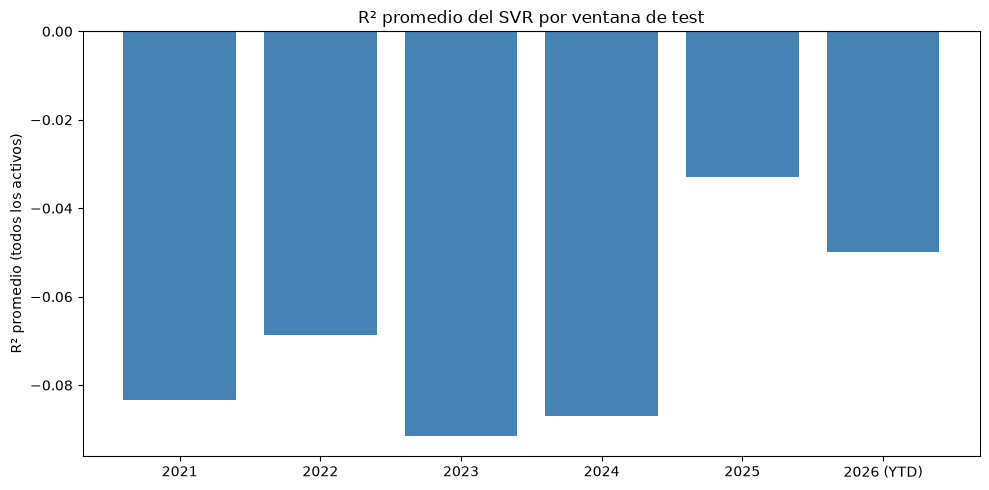

,R2_promedio,R2_mediana,pct_activos_R2_positivo
ventana,,,
2021,-0.0834,-0.0709,0.1364
2022,-0.0688,-0.0398,0.2273
2023,-0.0914,-0.0730,0.2500
2024,-0.0871,-0.0643,0.1136
2025,-0.0330,-0.0274,0.2727
2026 (YTD),-0.0499,-0.0222,0.2955


In [6]:
window_order = [w[0] for w in TEST_WINDOWS]

r2_summary = r2_df.groupby("ventana")["R2"].agg(
    R2_promedio="mean",
    R2_mediana="median",
    pct_activos_R2_positivo=lambda s: (s > 0).mean()
).reindex(window_order)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(r2_summary.index, r2_summary["R2_promedio"], color="steelblue")
ax.axhline(0, color="red", linestyle="--", alpha=0.6)
ax.set_title("R² promedio del SVR por ventana de test")
ax.set_ylabel("R² promedio (todos los activos)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_r2_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()

r2_summary.round(4)


## 2. Métricas de los portafolios por ventana

In [7]:
def pivot_metric(metric):
    return metrics_df.pivot(index="ventana", columns="estrategia", values=metric).reindex(window_order)

sharpe_table = pivot_metric("Sharpe")
return_table = pivot_metric("Retorno anualizado")
drawdown_table = pivot_metric("Máx. drawdown")

print("SHARPE RATIO por ventana")
display(sharpe_table.round(3))
print("RETORNO ANUALIZADO por ventana")
display(return_table.round(3))
print("MÁXIMO DRAWDOWN por ventana")
display(drawdown_table.round(3))


SHARPE RATIO por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + SVR,S&P 500
ventana,,,,
2021,2.263,2.170,1.614,1.732
2022,-0.414,-0.651,-0.534,-0.860
2023,1.870,2.081,2.020,1.584
2024,2.088,2.206,1.942,1.562
2025,0.951,1.276,0.630,0.802
2026 (YTD),1.457,1.009,1.589,1.150


RETORNO ANUALIZADO por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + SVR,S&P 500
ventana,,,,
2021,0.297,0.350,0.286,0.247
2022,-0.072,-0.143,-0.105,-0.188
2023,0.252,0.308,0.290,0.227
2024,0.230,0.439,0.235,0.218
2025,0.168,0.295,0.124,0.170
2026 (YTD),0.160,0.158,0.251,0.173


MÁXIMO DRAWDOWN por ventana


estrategia,Equal Weight,Markowitz (mu histórico),Markowitz + SVR,S&P 500
ventana,,,,
2021,-0.047,-0.096,-0.077,-0.052
2022,-0.202,-0.205,-0.239,-0.254
2023,-0.089,-0.096,-0.092,-0.103
2024,-0.048,-0.118,-0.071,-0.085
2025,-0.153,-0.210,-0.125,-0.189
2026 (YTD),-0.063,-0.084,-0.077,-0.091


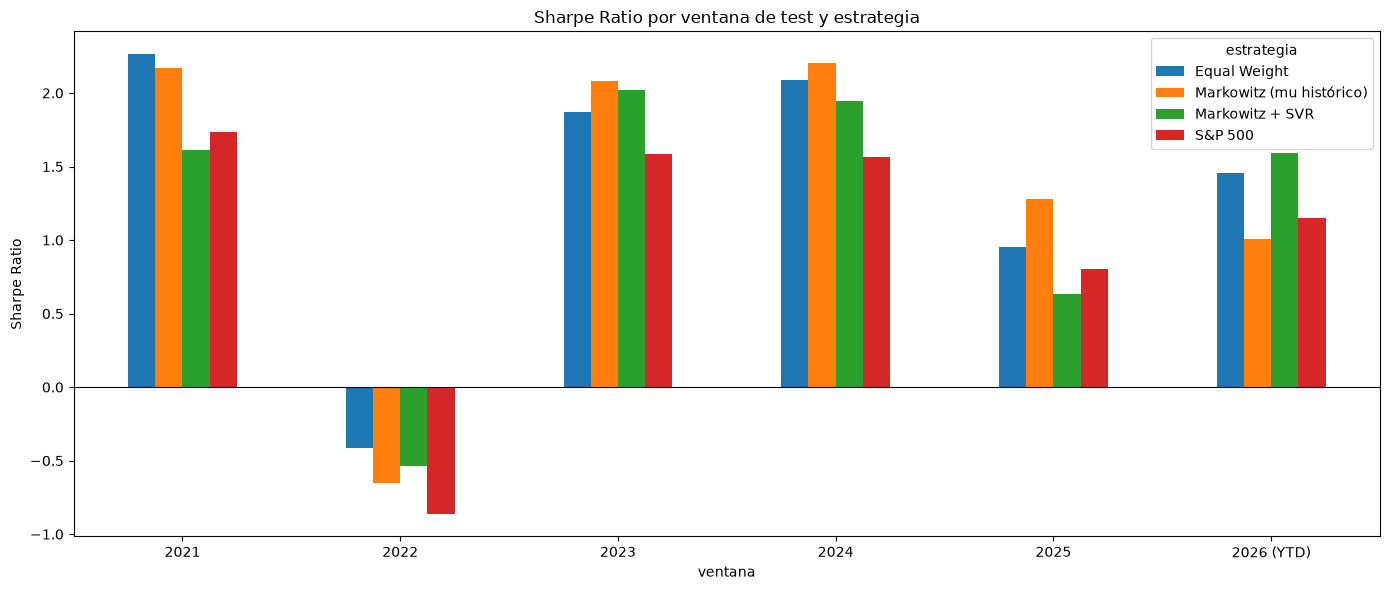

In [8]:
sharpe_table.plot(kind="bar", figsize=(14, 6), title="Sharpe Ratio por ventana de test y estrategia")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Sharpe Ratio")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_sharpe_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()


## 3. Crecimiento de $1 en cada ventana de test

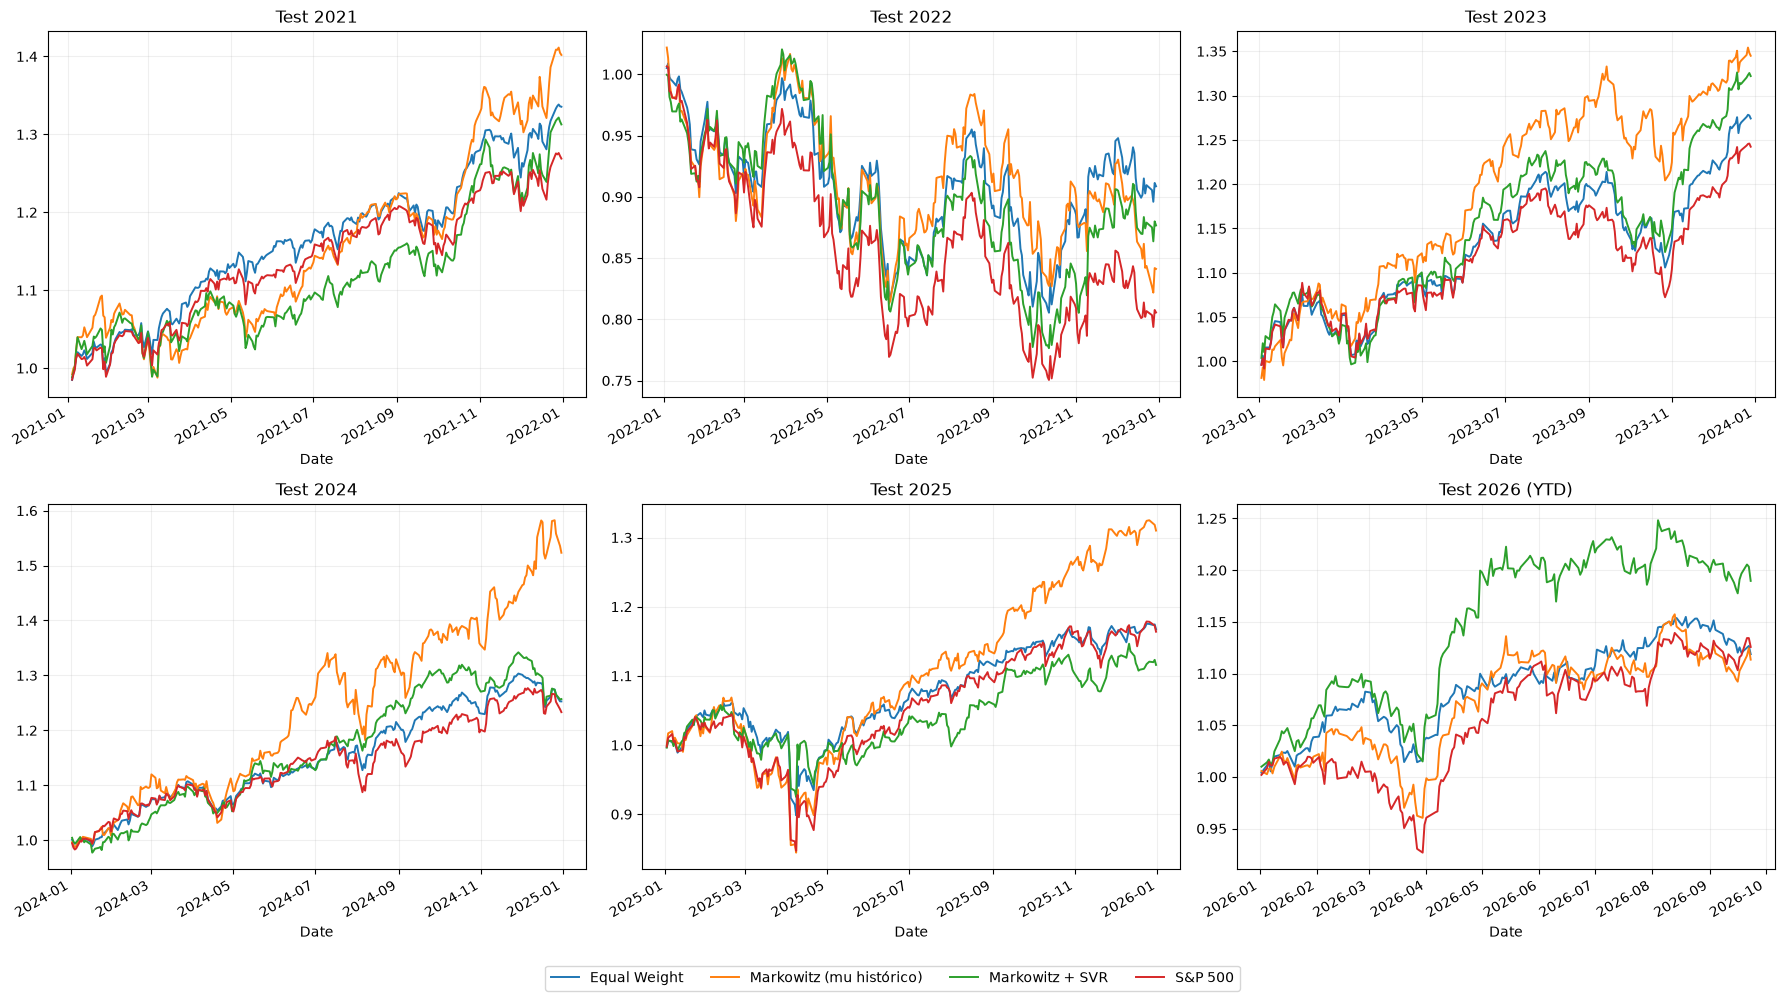

In [9]:
n = len(curves)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), squeeze=False)

for ax, (label, curve) in zip(axes.flatten(), curves.items()):
    curve.plot(ax=ax, linewidth=1.4, legend=False)
    ax.set_title(f"Test {label}")
    ax.grid(alpha=0.2)

for ax in axes.flatten()[n:]:
    ax.axis("off")

handles, labels = axes.flatten()[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(RESULTS_DIR / "03_curvas_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()


## 4. Consistencia entre ventanas (el resultado central)

La pregunta del profesor: ¿lo que se ve en una ventana se repite en las demás? Se cuenta en cuántas ventanas cada estrategia supera a Equal Weight y al S&P 500, y qué tan estable es su Sharpe.

In [10]:
consistency = pd.DataFrame({
    strategy: {
        "Sharpe promedio": sharpe_table[strategy].mean(),
        "Desv. est. del Sharpe": sharpe_table[strategy].std(),
        "Peor ventana (Sharpe)": sharpe_table[strategy].min(),
        "Ventanas que supera a Equal Weight": int((sharpe_table[strategy] > sharpe_table["Equal Weight"]).sum()),
        "Ventanas que supera al S&P 500": int((sharpe_table[strategy] > sharpe_table["S&P 500"]).sum()),
    }
    for strategy in sharpe_table.columns
}).T

print(f"Total de ventanas: {len(sharpe_table)}")
consistency.round(3)


Total de ventanas: 6


,Sharpe promedio,Desv. est. del Sharpe,Peor ventana (Sharpe),Ventanas que supera a Equal Weight,Ventanas que supera al S&P 500
Equal Weight,1.369,0.993,-0.414,0.0,6.0
Markowitz (mu histórico),1.349,1.101,-0.651,3.0,5.0
Markowitz + SVR,1.210,0.988,-0.534,2.0,4.0
S&P 500,0.995,0.971,-0.860,0.0,0.0


## 5. ¿El ranking de retornos esperados se parece a lo que realmente pasó?

Correlación de Spearman entre el `mu` con el que se decidió y el retorno realmente obtenido por cada activo durante el test. Cerca de 0 = no hay poder de ordenar ganadores y perdedores; positivo y consistente = hay algo de señal.

,Spearman mu histórico vs. realizado,Spearman mu SVR vs. realizado
ventana,,
2021,-0.014,-0.112
2022,-0.523,-0.053
2023,0.039,0.166
2024,0.185,0.114
2025,0.238,0.149
2026 (YTD),-0.114,0.119


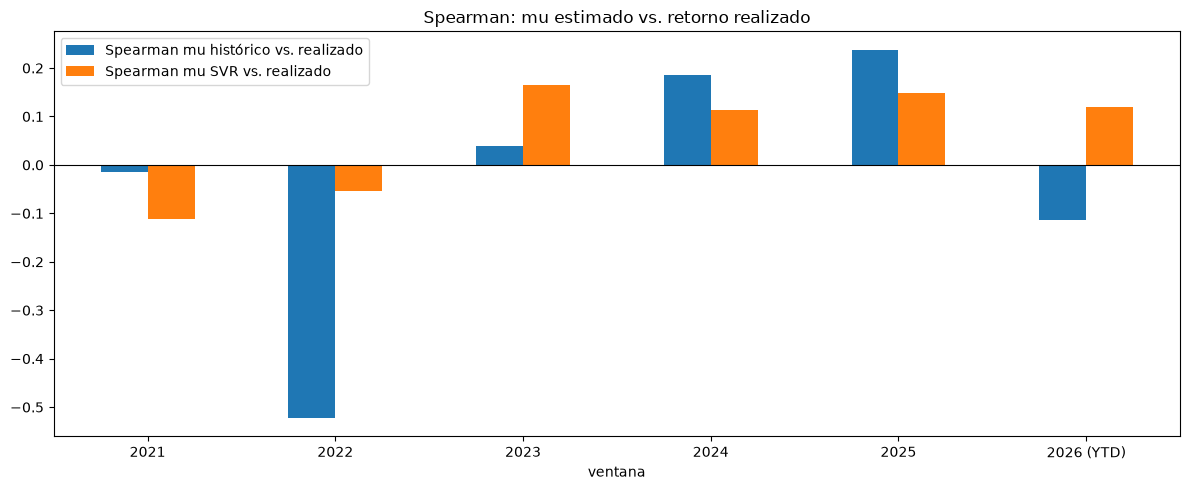

Ventanas donde Max Sharpe tuvo que usar el respaldo de mínima volatilidad:


,Markowitz hist usó fallback,Markowitz+SVR usó fallback
ventana,,
2021,False,False
2022,False,False
2023,False,False
2024,False,False
2025,False,False
2026 (YTD),False,False


In [11]:
display(signal_df.round(3))

signal_df.plot(kind="bar", figsize=(12, 5), title="Spearman: mu estimado vs. retorno realizado")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "04_spearman_por_ventana.png", dpi=300, bbox_inches="tight")
plt.show()

print("Ventanas donde Max Sharpe tuvo que usar el respaldo de mínima volatilidad:")
display(fallback_df)


## Cómo leer los resultados

- **R² por ventana**: si es negativo o cercano a 0 en todas, la falta de señal no es una casualidad del corte 2024.
- **Sharpe por ventana y consistencia**: si una estrategia gana en 2024 pero pierde en 2022, su desempeño depende del régimen de mercado, no del método.
- **Spearman**: mide directamente si `mu` ordena bien a los activos. Un valor que cambia de signo entre ventanas indica ruido.
- Con solo 6 ventanas (una de ellas parcial) las conclusiones son orientativas, no estadísticamente concluyentes. Conviene decirlo así en el informe.

## Guardar resultados

In [12]:
r2_df.to_csv(RESULTS_DIR / "r2_por_activo_y_ventana.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "metricas_por_ventana.csv", index=False)
sharpe_table.to_csv(RESULTS_DIR / "sharpe_por_ventana.csv")
consistency.to_csv(RESULTS_DIR / "consistencia_entre_ventanas.csv")
signal_df.to_csv(RESULTS_DIR / "spearman_por_ventana.csv")

for label, w in weights_store.items():
    w.to_csv(RESULTS_DIR / f"pesos_ventana_{label.replace(' ', '_').replace('(', '').replace(')', '')}.csv")

print("Resultados guardados en:", RESULTS_DIR)


Resultados guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\svr_ventanas_diversified
